In [1]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Resize, ToTensor
from torch.utils.data import Subset
from torchviz import make_dot

In [2]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRASNFORM = Compose([
    Resize((224, 224)),
    ToTensor()
])

In [3]:
trainDataset = ImageFolder(
    root=pathToData / 'dogsVsCats/train',
    transform=TRASNFORM
)
testDataset = ImageFolder(
    root=pathToData / 'dogsVsCats/test',
    transform=TRASNFORM
)
trainDataset = Subset(trainDataset, 
                      list(range(0, 2000)) + list(range(12500, 14500)))
testDataset = Subset(testDataset, 
                     list(range(0, 1000)) + list(range(2500, 3500)))
trainLoader = torch.utils.data.DataLoader(
    trainDataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
testLoader = torch.utils.data.DataLoader(
    testDataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [5]:
from utils import *
import torch
import torch.nn as nn
from torchvision import models

In [25]:
class dogsVsCatsModel(nn.Module):
    def __init__(self, pretrained=True, freeze_features=True):
        super(dogsVsCatsModel, self).__init__()

        self.regnet = models.regnet_y_400mf(pretrained=pretrained)
        if freeze_features:
            for param in self.regnet.parameters():
                param.requires_grad = False

        self.regnet.fc = nn.Linear(440, 2)

    def forward(self, x):
        x = self.regnet(x)
        return x

/home/jakub/Desktop/inz/algorythms/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/jakub/Desktop/inz/algorythms/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=RegNet_Y_400MF_Weights.IMAGENET1K_V1`. You can also use `weights=RegNet_Y_400MF_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


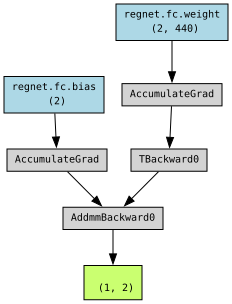

In [28]:
model = dogsVsCatsModel().to(DEVICE)
model.regnet.trunk_output.block4[-1].f.c[0]
make_dot(model(torch.randn(1, 3, 224, 224)), params=dict(model.named_parameters()), show_attrs=False, show_saved=False)

In [29]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 5, 'dogsVsCatsRegNet')

Epoch 1/5 - Train Loss: 0.0056, Train Accuracy: 0.8552 - Test Loss: 0.0030, Test Accuracy: 0.9415
Epoch 2/5 - Train Loss: 0.0025, Train Accuracy: 0.9543 - Test Loss: 0.0023, Test Accuracy: 0.9530
Epoch 3/5 - Train Loss: 0.0021, Train Accuracy: 0.9553 - Test Loss: 0.0019, Test Accuracy: 0.9565
Epoch 4/5 - Train Loss: 0.0019, Train Accuracy: 0.9557 - Test Loss: 0.0017, Test Accuracy: 0.9580
Epoch 5/5 - Train Loss: 0.0018, Train Accuracy: 0.9595 - Test Loss: 0.0016, Test Accuracy: 0.9650
